In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [2]:
df = pd.read_csv("netflix_titles_cleaned.csv")

In [3]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

df = df.dropna(subset=["date_added"])

df = df[
    df["type"]
    .str.strip()
    .str.lower()
    == "movie"
]

if df.empty:
    raise ValueError("No Movie data found in the dataset!")

In [4]:
df = df.sort_values("date_added")
daily_df = df.groupby("date_added").size().reset_index(name="Daily_Added")
daily_df["Cumulative_Movies"] = daily_df["Daily_Added"].cumsum()

daily_df["Date_num"] = (
    daily_df["date_added"] - daily_df["date_added"].min()
).dt.days

print("\nNetflix Movies Time-Series Dataset:")
print(daily_df.head())


Netflix Movies Time-Series Dataset:
  date_added  Daily_Added  Cumulative_Movies  Date_num
0 2008-01-01            1                  1         0
1 2009-05-05            1                  2       490
2 2009-11-18            1                  3       687
3 2010-11-01            1                  4      1035
4 2011-05-17            1                  5      1232


In [5]:

X = daily_df[["Date_num"]]
y = daily_df["Cumulative_Movies"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


reg = linear_model.LinearRegression()
reg.fit(X_train, y_train)

print("\nModel trained successfully!")


y_pred = reg.predict(X_test)

print("\nPredicted Cumulative Movies:")
print(y_pred)

result = X_test.copy()
result["Actual_Movies"] = y_test
result["Predicted_Movies"] = y_pred

print("\nActual vs Predicted Movies:")
print(result)


mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

print("\nCoefficient:", reg.coef_)
print("Intercept:", reg.intercept_)




Training data: (1226, 1)
Testing data: (307, 1)

Model trained successfully!

Predicted Cumulative Movies:
[ 3212.49833583  -144.19944349  1313.41717975  2627.3619136
  1692.1885245   3429.31227799  2885.97131449  5273.53689449
  4291.34361431  4651.82944587  3946.53107978  2622.13748125
  1519.78225723  5216.06813873  2504.58775357  3930.85778276
  4432.40328753 -1105.49499429  -564.76624696   999.95123927
  1292.51945038  1457.08906914   375.63157448  1561.57771596
  1942.96127688  -227.79036095  2345.24256716  3964.81659298
  3774.12481252  3625.22849079  4181.63053515  3053.15314942
  4192.07939983  2332.18148631  5200.39484171  1971.69565476
  4610.03398714  2593.40310338  1989.98116795  3013.96990686
  2972.17444812  3653.96286867  3486.78103375  5038.43743913
  1459.70128531  1091.37880524  -374.0744665   2363.52808036
  5132.47722127  5244.80251661  1086.1543729   2912.0934762
  4380.15896412  1757.49392876  3849.87908147  1872.43144027
  -546.48073377  2572.50537401  1430.966

In [ ]:

future_date = pd.Timestamp("2022-01-01")

future_date_num = (
    future_date - daily_df["date_added"].min()
).days

future_prediction = reg.predict(
    pd.DataFrame({
        "Date_num": [future_date_num]
    })
)

print(
    "\nPredicted Cumulative Movies on 2022-01-01:",
    round(future_prediction[0])
)


prediction_df = pd.DataFrame({
    "Date": daily_df.loc[X_test.index, "date_added"],
    "Actual_Movies": y_test,
    "Predicted_Movies": y_pred
})

prediction_df = prediction_df.sort_values("Date")

future_df = pd.DataFrame({
    "Date": [future_date],
    "Actual_Movies": [np.nan],
    "Predicted_Movies": [future_prediction[0]]
})

prediction_df = pd.concat(
    [prediction_df, future_df],
    ignore_index=True
)

prediction_df.to_csv(
    "netflix_movies_predictions.csv",
    index=False
)

print("\nCSV file saved successfully!")
print("\nPrediction Results:")
print(prediction_df.tail())




Predicted Cumulative Movies on 2022-01-01: 5626

CSV file saved successfully!

Prediction Results:
          Date  Actual_Movies  Predicted_Movies
303 2021-09-14         6091.0       5341.454515
304 2021-09-15         6105.0       5344.066731
305 2021-09-16         6113.0       5346.678947
306 2021-09-19         6118.0       5354.515596
307 2022-01-01            NaN       5626.186078


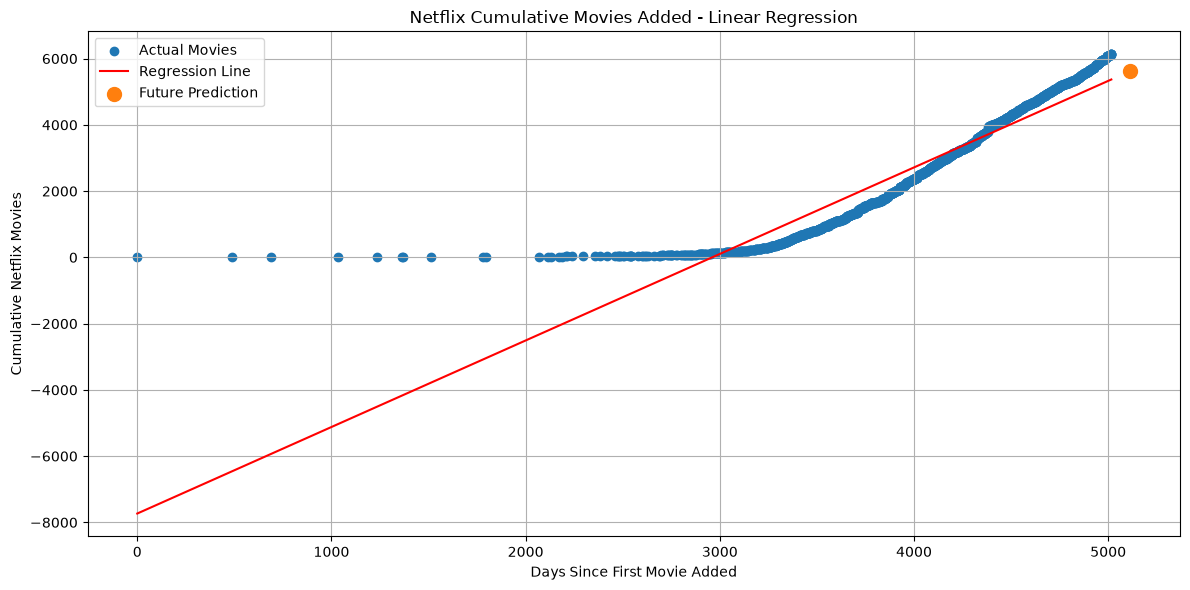

In [ ]:

plt.figure(figsize=(12, 6))

plt.scatter(
    daily_df["Date_num"],
    daily_df["Cumulative_Movies"],
    label="Actual Movies"
)

date_range = np.linspace(
    daily_df["Date_num"].min(),
    daily_df["Date_num"].max(),
    200
)

date_range_df = pd.DataFrame({
    "Date_num": date_range
})

regression_predictions = reg.predict(date_range_df)

plt.plot(
    date_range,
    regression_predictions,
    color="red",
    label="Regression Line"
)


plt.scatter(
    future_date_num,
    future_prediction[0],
    s=100,
    label="Future Prediction"
)

plt.xlabel("Days Since First Movie Added")
plt.ylabel("Cumulative Netflix Movies")
plt.title("Netflix Cumulative Movies Added - Linear Regression")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()